# GraphSAGE K-sweep on the F1 KGs

How does message-passing depth interact with the way each KG is built? Every KG keeps **its own tuned
configuration** from `GraphSAGE`'s tuning run (hidden dim, bases, lr, weight decay), and only the number of
layers K changes, over K = 1-4 (`hidden_list = [hidden_dim] * (K - 1)`; K = 1 has no hidden layer).

Pure SULO puts the same facts further from a `RaceEntry`, so a fixed depth sees less of an entry in Pure.
Hops from `RaceEntry/26500` to its own facts in the masked graphs:

| Fact of the entry | Ad-hoc | Hybrid | Pure |
|---|---|---|---|
| race, driver, team, session results | 1 | 1 | 1-2 (driver/team behind a Role node) |
| grid rank value | 2 | 3 | 3 |
| lap times, session type, race date/round | 2 | 2 | 3 |
| circuit name/country, season year | 3 | 3 | 4 |

K = 4 is the smallest depth that reaches every fact of an entry in all three KGs.

**Protocol** (the same as tuning phases 3-4, `gnn_tools.run_k_sweep`): per KG and K, train once per
`TUNING_SEEDS` seed with early stopping on val (mean val ROC-AUC, median best epoch), then retrain on
train+val for that epoch count and test once per `FINAL_SEEDS` seed (mean ± std). Early stopping has a
50-epoch warm-up, as in the ablation (see the constants). At each KG's tuned depth (GraphSAGE: 3 for every KG) this
is the tuning run's own winner, whose seeds all peaked after the warm-up, so those rows are **copied from the
tuning CSV** (`reused`), not re-run.
GraphSAGE has no relation types, so it has no basis decomposition (`num_bases` None). This notebook and its R-GCN counterpart differ only in the model.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch

from f1_node_data import build_kg_data, load_population, race_entry_labels, stratified_split
from node_prediction.gnn_tools import (
    cleanup, limit_cuda_memory_to_free_vram, run_k_sweep, summarize_k_sweep, tuned_winner,
)
from node_prediction.models import GraphSAGEModel

KGS = ["adhoc", "pure_sulo", "hybrid_sulo"]
TUNING_DIR = ROOT / "outputs" / "f1" / "node_prediction" / "graphsage"
OUT_DIR = ROOT / "outputs" / "f1" / "node_prediction" / "k_sweep" / "graphsage"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the sweep could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

The same graphs as the main notebooks (`build_kg_data`: the label and race outcomes masked, the shared
stratified split), so their shuffled-label check covers these graphs too.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
labels = race_entry_labels(assertions)
split = stratified_split(labels, seed=42)

kg_data = {kg: build_kg_data(kg, entities, assertions, split) for kg in KGS}

pd.DataFrame({
    kg: {
        "nodes": d.data.num_nodes,
        "edges (fwd + inv)": d.data.edge_index.size(1),
        "relation types (fwd + inv)": d.num_relations,
        "train / val / test": f"{len(d.train)} / {len(d.val)} / {len(d.test)}",
    }
    for kg, d in kg_data.items()
}).T

,nodes,edges (fwd + inv),relation types (fwd + inv),train / val / test
adhoc,57946,432642,52,21625 / 2703 / 2704
pure_sulo,148910,888842,24,21625 / 2703 / 2704
hybrid_sulo,57985,525162,58,21625 / 2703 / 2704


## Constants

The training constants are the main notebook's, with the same sources. Each KG's configuration is its
tuning winner, read from `graphsage/<kg>_sequential_tuning_results.csv`, not hardcoded.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4); Kipf & Welling 2017 cap at 200. Patience 50: no
# literature value (user choice, 2026-10-21). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
#   https://arxiv.org/abs/1609.02907
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29), as in the ablation: epochs 0-49 are trained but neither
# checkpointed nor counted towards patience, as Keras' EarlyStopping(start_from_epoch). Without it, the first
# GraphSAGE K-sweep run kept val spikes from epochs 2-6 as the score to beat at 4 depths (e.g. Ad-hoc K=2 seed 1:
# 0.682 at epoch 4, passed at epoch 114, best 0.785), and Pure K=2 retrained for 5 epochs. 50 is a user choice
# with no literature value. The main tuning has no warm-up; tuned_winner checks that every winner seed peaked
# after it, so the reused rows are what the warm-up would give.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim).
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's GraphSAGE ogbn-products example uses p=0.5; Hamilton et al. 2017 do not
# report dropout.
#   https://github.com/pyg-team/pytorch_geometric/blob/2.3.0/examples/ogbn_products_sage.py
DROPOUT = 0.5

# The main notebooks' seeds: tuning seeds (user, 2026-10-24) score a config by its mean val ROC-AUC
# and set the retrain length (median best epoch); final seeds (user, 2026-10-20) give mean ± std.
TUNING_SEEDS = [0, 1, 2]
FINAL_SEEDS = [0, 1, 2, 3, 4]

# Depths (user, 2026-10-29): 1-3 are the main tuning's depths; 4 is the smallest depth that reaches every
# fact of a RaceEntry in all three KGs (Pure: circuit and season attributes, table above), and is in
# GraphGym's message-passing-layer design space {2, 4, 6, 8} (You et al. 2020, Section 4).
#   https://arxiv.org/abs/2011.08843
K_VALUES = [1, 2, 3, 4]

tuning = {kg: pd.read_csv(TUNING_DIR / f"{kg}_sequential_tuning_results.csv") for kg in KGS}
pd.DataFrame({kg: tuned_winner(df, TUNING_SEEDS, FINAL_SEEDS, START_FROM_EPOCH)[0] for kg, df in tuning.items()}).T

,hidden_dim,layers,num_bases,lr,weight_decay
adhoc,64.0,3.0,NaN,0.010,0.0000
pure_sulo,512.0,3.0,NaN,0.001,0.0001
hybrid_sulo,512.0,3.0,NaN,0.010,0.0000


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh model for one KG; everything KG-specific is bound here."""
    def build(hidden_list, bases):
        return GraphSAGEModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            num_relations=d.num_relations, num_bases=bases, dropout=DROPOUT,
        )
    return build

## Sweep runs

Rows are appended to `k_sweep_results.csv` after each (KG, K): after a crash, finished ones are skipped and
partial or failed ones are re-run. Constants are not checked, so move the CSV away after changing one.

In [5]:
csv_path = OUT_DIR / "k_sweep_results.csv"
for kg, d in kg_data.items():
    results = run_k_sweep(
        model_factory(d), d, kg, tuning[kg], K_VALUES, epochs=EPOCHS, patience=PATIENCE,
        start_from_epoch=START_FROM_EPOCH, tuning_seeds=TUNING_SEEDS, final_seeds=FINAL_SEEDS,
        save_dir=f"{OUT_DIR / kg}/", csv_path=csv_path,
    )
    cleanup()

results = pd.read_csv(csv_path)   # every KG's rows
# An OOM-ed K is logged, not fatal: every KG needs every K to be compared.
failed = results[results["status"] != "ok"]
assert failed.empty, f"K-sweep runs that did not finish:\n{failed[['kg', 'K', 'phase', 'status']]}"
assert len(results) == len(KGS) * len(K_VALUES) * (1 + len(FINAL_SEEDS))
# Rows are resumed, not re-run: a row from before the warm-up with a seed peaking inside it must be re-run.
tune = results[results["phase"] == "tune"]
early = tune[tune["best_epoch_seeds"].map(lambda e: min(int(x) for x in str(e).split(";")) < START_FROM_EPOCH)]
assert early.empty, f"Rows selected inside the warm-up (delete and re-run them):\n{early[['kg', 'K', 'best_epoch_seeds']]}"


=== K-sweep adhoc | K=1 ===
Epoch 000 | Train Loss: 0.6444 | Val Loss: 1.0984 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.6976 | Grad Norm: 2.2338
Epoch 001 | Train Loss: 1.0974 | Val Loss: 0.7576 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.7003 | Grad Norm: 5.3871
Epoch 002 | Train Loss: 0.7560 | Val Loss: 0.6547 | Val Acc: 0.6408 | Val F1: 0.4908 | Val ROC-AUC: 0.7012 | Grad Norm: 3.8815
Epoch 003 | Train Loss: 0.6523 | Val Loss: 0.8439 | Val Acc: 0.3130 | Val F1: 0.4768 | Val ROC-AUC: 0.7022 | Grad Norm: 2.9092
Epoch 004 | Train Loss: 0.8405 | Val Loss: 0.6790 | Val Acc: 0.6145 | Val F1: 0.4743 | Val ROC-AUC: 0.7027 | Grad Norm: 6.4175
Epoch 005 | Train Loss: 0.6750 | Val Loss: 0.6048 | Val Acc: 0.6878 | Val F1: 0.0806 | Val ROC-AUC: 0.7029 | Grad Norm: 3.6271
Epoch 006 | Train Loss: 0.6008 | Val Loss: 0.6896 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.7030 | Grad Norm: 0.8650
Epoch 007 | Train Loss: 0.6855 | Val Loss: 0.7289 | Val Acc: 0.6870 | Val F1: 0.00

## Results

Per KG and K: mean val ROC-AUC over the tuning seeds, then test metrics as mean ± std over the final seeds
(no significance test, as in the main notebooks). `reused` marks the tuned depth, copied from the tuning run.

In [6]:
summary = summarize_k_sweep(results)
summary.round(4).to_csv(OUT_DIR / "k_sweep_summary.csv")
summary.round(4)

val_roc_auc  val_roc_auc_std  n_seeds  best_epoch  reused  \
kg          K                                                              
adhoc       1       0.7063           0.0000        5         119   False   
            2       0.7912           0.0056        5         379   False   
            3       0.8265           0.0011        5         331    True   
            4       0.8286           0.0001        5         282   False   
hybrid_sulo 1       0.7067           0.0000        5          70   False   
            2       0.7863           0.0029        5         366   False   
            3       0.8249           0.0040        5         383    True   
            4       0.8225           0.0037        5         222   False   
pure_sulo   1       0.6059           0.0500        5          76   False   
            2       0.6927           0.0109        5         120   False   
            3       0.7500           0.0018        5         395    True   
            4       0.7466           0.0151        5         353   False   

              ended_by_epoch_cap  test_roc_auc_mean  test_roc_auc_std  \
kg          K                                                           
adhoc       1              False             0.7276            0.0000   
            2               True             0.8207            0.0035   
            3              False             0.8628            0.0019   
            4              False             0.8621            0.0005   
hybrid_sulo 1              False             0.6891            0.0870   
            2               True             0.8155            0.0044   
            3               True             0.8593            0.0078   
            4               True             0.8473            0.0134   
pure_sulo   1              False             0.6411            0.0532   
            2               True             0.7052            0.0082   
            3               True             0.7816            0.0019   
            4               True             0.7834            0.0039   

               test_pr_auc_mean  test_pr_auc_std  test_f1_mean  test_f1_std  \
kg          K                                                                 
adhoc       1            0.5180           0.0000        0.1041       0.0000   
            2            0.6432           0.0050        0.5363       0.0199   
            3            0.7302           0.0021        0.6504       0.0374   
            4            0.7237           0.0035        0.6780       0.0253   
hybrid_sulo 1            0.4816           0.0812        0.1027       0.0143   
            2            0.6388           0.0078        0.5780       0.0277   
            3            0.7256           0.0101        0.6600       0.0166   
            4            0.7008           0.0316        0.5700       0.1435   
pure_sulo   1            0.4197           0.0521        0.0923       0.0000   
            2            0.4825           0.0114        0.1486       0.2024   
            3            0.6005           0.0034        0.4388       0.1118   
            4            0.5981           0.0087        0.4508       0.0823   

               test_accuracy_mean  test_accuracy_std  num_parameters  
kg          K                                                         
adhoc       1              0.6882             0.0000        642563.0  
            2              0.7549             0.0036        675137.0  
            3              0.7991             0.0040        683393.0  
            4              0.8013             0.0012        691649.0  
hybrid_sulo 1              0.6867             0.0006        645635.0  
            2              0.7548             0.0063        909825.0  
            3              0.7929             0.0216       1434625.0  
            4              0.7778             0.0281       1959425.0  
pure_sulo   1              0.6871             0.0000        650755.0  
            2              0.6804      

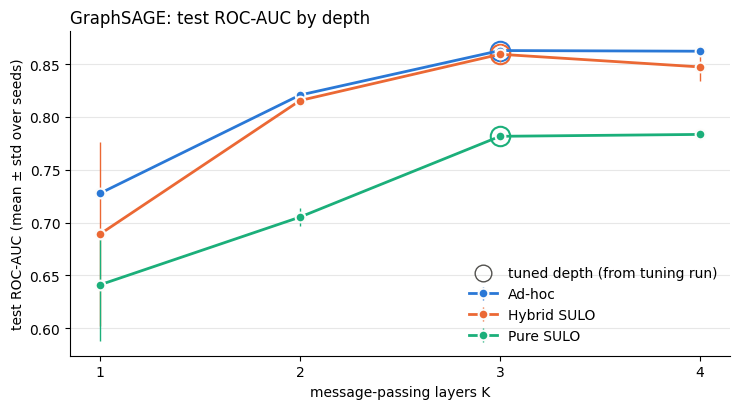

In [7]:
names = {"adhoc": "Ad-hoc", "hybrid_sulo": "Hybrid SULO", "pure_sulo": "Pure SULO"}
colors = {"adhoc": "#2a78d6", "hybrid_sulo": "#eb6834", "pure_sulo": "#1baf7a"}   # fixed per KG
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for kg in ["adhoc", "hybrid_sulo", "pure_sulo"]:
    s = summary.loc[kg]
    ax.errorbar(s.index, s["test_roc_auc_mean"], yerr=s["test_roc_auc_std"], color=colors[kg], linewidth=2,
                marker="o", markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=1.5,
                elinewidth=1, capsize=0, label=names[kg])
    tuned = s[s["reused"]]
    ax.plot(tuned.index, tuned["test_roc_auc_mean"], linestyle="none", marker="o", markersize=14,
            markerfacecolor="none", markeredgecolor=colors[kg], markeredgewidth=1.5)
ax.plot([], [], linestyle="none", marker="o", markersize=12, markerfacecolor="none",
        markeredgecolor="#52514e", label="tuned depth (from tuning run)")
ax.set_xticks(K_VALUES)
ax.set_xlabel("message-passing layers K")
ax.set_ylabel("test ROC-AUC (mean ± std over seeds)")
ax.set_title("GraphSAGE: test ROC-AUC by depth", loc="left")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "k_sweep_test_roc_auc.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A tuning seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its K's val score and retrain length may be understated (the same limitation as in the main notebooks).

In [8]:
tune = results[results["phase"] == "tune"]
tune[tune["ended_by_epoch_cap"]][["kg", "K", "reused", "val_roc_auc", "best_epoch_seeds"]]

,kg,K,reused,val_roc_auc,best_epoch_seeds
6,adhoc,2,False,0.791158,367;393;379
30,pure_sulo,2,False,0.692713,55;120;394
36,pure_sulo,3,True,0.750005,395;386;397
42,pure_sulo,4,False,0.746575,353;128;393
54,hybrid_sulo,2,False,0.786323,314;399;366
60,hybrid_sulo,3,True,0.824903,387;383;331
66,hybrid_sulo,4,False,0.822495,195;222;385
